In [1]:
import pandas as pd
import numpy as np

# 1. Load the clean data
loans = pd.read_parquet("../data/processed/loans_clean.parquet")

# 2. Keep only MATURE loans (final outcome known for every loan)
is_mature = (
    ((loans["term"] == 36) & (loans["issue_year"] <= 2015)) |
    ((loans["term"] == 60) & (loans["issue_year"] <= 2013))
)
df = loans[is_mature].copy()
del loans  # free memory

# 3. Sub-grade as a number (A1 = 1 ... G5 = 35)
sub_grade_order = [f"{g}{n}" for g in "ABCDEFG" for n in range(1, 6)]
df["sub_grade_num"] = df["sub_grade"].map({sg: i + 1 for i, sg in enumerate(sub_grade_order)})

# 4. Features: ONLY information known at the time of application (no leakage)
NUMERIC = [
    "loan_amnt", "term", "int_rate", "installment", "sub_grade_num",
    "annual_inc", "dti", "fico_avg", "emp_years", "emp_length_missing",
    "open_acc", "total_acc", "revol_bal", "revol_util", "pub_rec",
    "pub_rec_bankruptcies", "delinq_2yrs", "inq_last_6mths", "mort_acc",
    "credit_history_years", "loan_to_income", "payment_to_income",
]
CATEGORICAL = ["home_ownership", "verification_status", "purpose", "addr_state"]
TARGET = "is_default"

# 5. Time-based split: learn from the past, test on the future
train = df[df["issue_year"] <= 2013].reset_index(drop=True)
test = df[df["issue_year"].between(2014, 2015)].reset_index(drop=True)

print("Mature loans:", len(df))
print(f"Train (2007–2013): {len(train):,} loans | default rate {train[TARGET].mean():.2%}")
print(f"Test  (2014–2015): {len(test):,} loans | default rate {test[TARGET].mean():.2%}")
print("Features:", len(NUMERIC) + len(CATEGORICAL))

Mature loans: 676034
Train (2007–2013): 230,677 loans | default rate 15.65%
Test  (2014–2015): 445,357 loans | default rate 14.46%
Features: 26


In [2]:
from sklearn.metrics import roc_auc_score

# Baseline: use Lending Club's own sub-grade (and interest rate) as the risk score
auc_subgrade = roc_auc_score(test[TARGET], test["sub_grade_num"])
auc_int_rate = roc_auc_score(test[TARGET], test["int_rate"])

print(f"Baseline AUC — sub-grade alone    : {auc_subgrade:.4f}")
print(f"Baseline AUC — interest rate alone: {auc_int_rate:.4f}")

Baseline AUC — sub-grade alone    : 0.6712
Baseline AUC — interest rate alone: 0.6675


In [3]:
import time
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

X_train, y_train = train[NUMERIC + CATEGORICAL], train[TARGET]
X_test, y_test = test[NUMERIC + CATEGORICAL], test[TARGET]

# Preprocessing: numeric -> fill missing + scale, categorical -> one-hot
preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
])

logreg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000)),
])

start = time.time()
logreg.fit(X_train, y_train)
p_logreg = logreg.predict_proba(X_test)[:, 1]
auc_logreg = roc_auc_score(y_test, p_logreg)

print(f"Training time: {time.time() - start:.1f} seconds")
print(f"Logistic Regression AUC : {auc_logreg:.4f}")
print(f"Baseline (sub-grade) AUC: {auc_subgrade:.4f}")
print(f"Improvement             : {auc_logreg - auc_subgrade:+.4f}")

Training time: 5.1 seconds
Logistic Regression AUC : 0.6764
Baseline (sub-grade) AUC: 0.6712
Improvement             : +0.0052


In [4]:
from xgboost import XGBClassifier

# XGBoost handles categories natively: convert text columns to 'category' type
# (test uses the same categories as train, so the encoding is consistent)
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()
for col in CATEGORICAL:
    categories = X_train_xgb[col].astype("category").cat.categories
    X_train_xgb[col] = pd.Categorical(X_train_xgb[col], categories=categories)
    X_test_xgb[col] = pd.Categorical(X_test_xgb[col], categories=categories)

xgb = XGBClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=50,
    tree_method="hist",
    enable_categorical=True,
    eval_metric="auc",
    n_jobs=-1,
    random_state=42,
)

start = time.time()
xgb.fit(X_train_xgb, y_train)
p_xgb = xgb.predict_proba(X_test_xgb)[:, 1]
auc_xgb = roc_auc_score(y_test, p_xgb)

print(f"Training time: {time.time() - start:.1f} seconds")
print(f"XGBoost AUC             : {auc_xgb:.4f}")
print(f"Logistic Regression AUC : {auc_logreg:.4f}")
print(f"Baseline (sub-grade) AUC: {auc_subgrade:.4f}")
print(f"Improvement vs baseline : {auc_xgb - auc_subgrade:+.4f}")

C:\Users\Naman\AppData\Local\Temp\ipykernel_20784\1085653390.py:10: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X_test_xgb[col] = pd.Categorical(X_test_xgb[col], categories=categories)


Training time: 23.8 seconds
XGBoost AUC             : 0.6834
Logistic Regression AUC : 0.6764
Baseline (sub-grade) AUC: 0.6712
Improvement vs baseline : +0.0121


In [5]:
# 1. Model comparison (Gini = 2 x AUC - 1, a common credit-risk metric)
comparison = pd.DataFrame({
    "Model": ["Sub-grade (Lending Club)", "Logistic Regression", "XGBoost"],
    "AUC": [auc_subgrade, auc_logreg, auc_xgb],
})
comparison["Gini"] = 2 * comparison["AUC"] - 1
print(comparison.round(4).to_string(index=False), "\n")

# 2. Risk decile table on the test loans (1 = safest 10%, 10 = riskiest 10%)
results = test[["id", "grade", "sub_grade", "int_rate", "funded_amnt", "net_profit", TARGET]].copy()
results["pd_xgb"] = p_xgb
results["risk_decile"] = pd.qcut(results["pd_xgb"], 10, labels=range(1, 11))

deciles = results.groupby("risk_decile", observed=True).agg(
    loans=("id", "count"),
    avg_predicted_pd=("pd_xgb", "mean"),
    actual_default_rate=(TARGET, "mean"),
    avg_int_rate=("int_rate", "mean"),
    funded=("funded_amnt", "sum"),
    profit=("net_profit", "sum"),
)
deciles["return_pct"] = deciles["profit"] / deciles["funded"] * 100
deciles["avg_predicted_pd"] = (deciles["avg_predicted_pd"] * 100).round(2)
deciles["actual_default_rate"] = (deciles["actual_default_rate"] * 100).round(2)
deciles["avg_int_rate"] = deciles["avg_int_rate"].round(2)
deciles["return_pct"] = deciles["return_pct"].round(2)

top_vs_bottom = deciles["actual_default_rate"].iloc[-1] / deciles["actual_default_rate"].iloc[0]
print(f"Riskiest 10% default {top_vs_bottom:.1f}x more often than the safest 10%\n")

deciles[["loans", "avg_predicted_pd", "actual_default_rate", "avg_int_rate", "return_pct"]]

                   Model    AUC   Gini
Sub-grade (Lending Club) 0.6712 0.3425
     Logistic Regression 0.6764 0.3528
                 XGBoost 0.6834 0.3668 

Riskiest 10% default 9.2x more often than the safest 10%



,loans,avg_predicted_pd,actual_default_rate,avg_int_rate,return_pct
risk_decile,,,,,
1,44536,2.680000,3.30,6.71,7.34
2,44536,4.640000,5.95,7.91,7.70
3,44535,6.430000,8.13,9.21,8.20
4,44536,8.210000,10.08,10.37,8.60
5,44536,10.060000,11.93,11.41,8.69
6,44535,12.090000,14.61,12.37,8.07
7,44536,14.400000,16.97,13.22,7.63
8,44535,17.160000,19.82,14.04,6.82
9,44536,20.940001,23.41,15.00,5.75


                 feature  mean_abs_shap
0          sub_grade_num         0.3120
1             annual_inc         0.1729
2                   term         0.1280
3               int_rate         0.1268
4             addr_state         0.1044
5         loan_to_income         0.1012
6         inq_last_6mths         0.0778
7                    dti         0.0757
8               open_acc         0.0723
9                purpose         0.0722
10              fico_avg         0.0715
11  credit_history_years         0.0425
12             revol_bal         0.0413
13             emp_years         0.0409
14        home_ownership         0.0365 



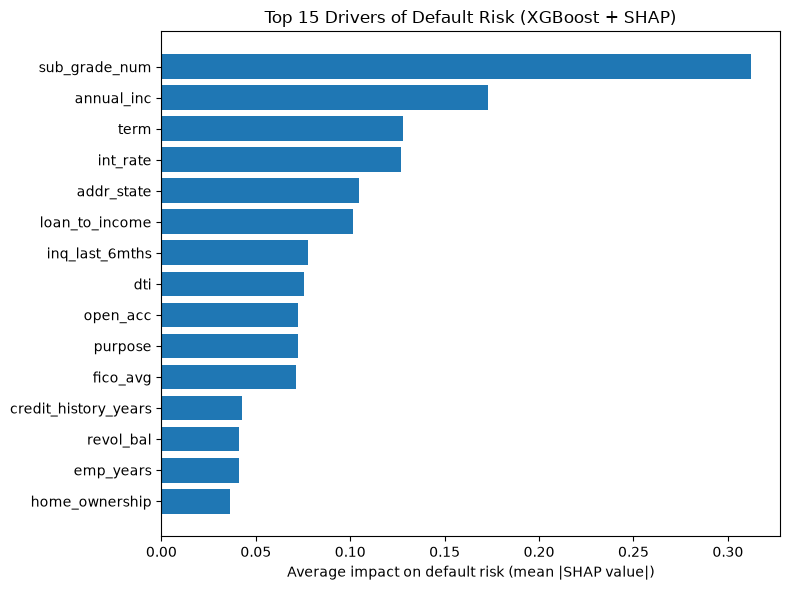

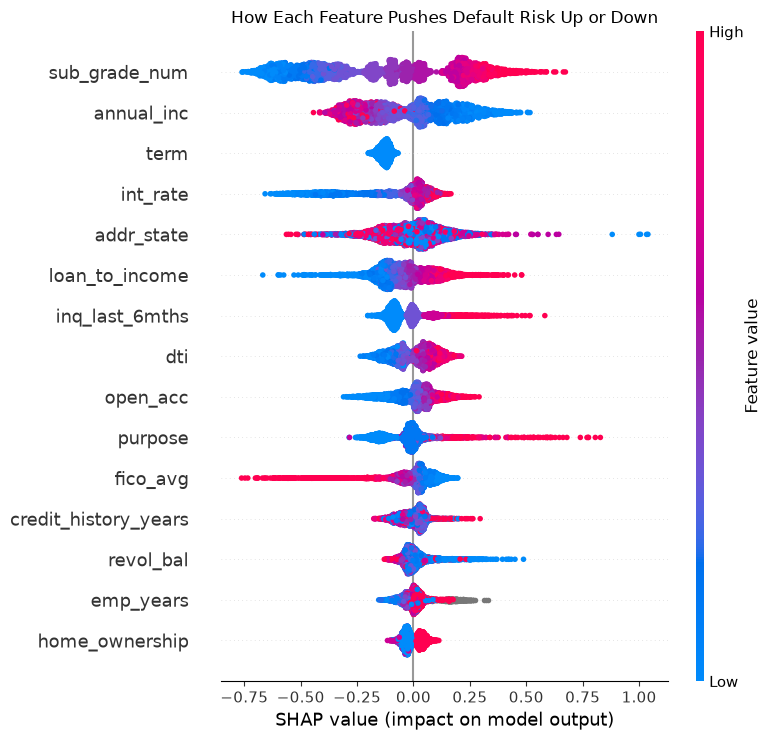

In [6]:
import matplotlib.pyplot as plt
import shap
import xgboost as xgblib

# 1. Sample 5,000 test loans (enough for stable explanations, light on memory)
sample = X_test_xgb.sample(5000, random_state=42)

# 2. SHAP values from XGBoost's built-in TreeSHAP (handles categorical features)
dmatrix = xgblib.DMatrix(sample, enable_categorical=True)
contribs = xgb.get_booster().predict(dmatrix, pred_contribs=True)
shap_values = contribs[:, :-1]  # last column is the base value

# 3. Feature importance = average absolute SHAP value
importance = (
    pd.DataFrame({"feature": sample.columns, "mean_abs_shap": np.abs(shap_values).mean(axis=0)})
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)
print(importance.head(15).round(4).to_string(), "\n")

# 4. Chart 1: top 15 features (bar chart)
top15 = importance.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top15["feature"], top15["mean_abs_shap"], color="#1f77b4")
plt.xlabel("Average impact on default risk (mean |SHAP value|)")
plt.title("Top 15 Drivers of Default Risk (XGBoost + SHAP)")
plt.tight_layout()
plt.savefig("../images/shap_importance.png", dpi=150)
plt.show()

# 5. Chart 2: SHAP summary (direction of each feature's effect)
sample_plot = sample.copy()
for col in CATEGORICAL:
    sample_plot[col] = sample_plot[col].cat.codes  # numeric codes for colouring
shap.summary_plot(shap_values, sample_plot, max_display=15, show=False)
plt.title("How Each Feature Pushes Default Risk Up or Down")
plt.tight_layout()
plt.savefig("../images/shap_summary.png", dpi=150)
plt.show()

In [7]:
import os

# 1. Save test-loan predictions for Phase 7 (policy simulation + Excel)
results["actual_return_pct"] = (results["net_profit"] / results["funded_amnt"] * 100).round(2)
results.to_parquet("../data/processed/test_predictions.parquet", index=False)

# 2. Save the decile table (used in the docs and Excel)
deciles.to_csv("../data/processed/risk_deciles.csv")

# 3. Save the trained XGBoost model
os.makedirs("../models", exist_ok=True)
xgb.save_model("../models/xgb_default_model.json")

# 4. Save the model comparison and feature importance
comparison.to_csv("../data/processed/model_comparison.csv", index=False)
importance.to_csv("../data/processed/shap_feature_importance.csv", index=False)

print("Saved:")
for path in [
    "../data/processed/test_predictions.parquet",
    "../data/processed/risk_deciles.csv",
    "../data/processed/model_comparison.csv",
    "../data/processed/shap_feature_importance.csv",
    "../models/xgb_default_model.json",
]:
    print(f"  {path}  ({os.path.getsize(path) / 1024:.0f} KB)")
print("\nRows in test predictions:", len(results))

Saved:
  ../data/processed/test_predictions.parquet  (9511 KB)
  ../data/processed/risk_deciles.csv  (1 KB)
  ../data/processed/model_comparison.csv  (0 KB)
  ../data/processed/shap_feature_importance.csv  (1 KB)
  ../models/xgb_default_model.json  (1412 KB)

Rows in test predictions: 445357
